# Beyond Spark (Polars, DuckDB, Ray Data & Daft)

Spark was built for clusters of hundreds of machines. Many data sets of today fit on one laptop: two months of NYC
taxi trips are 6 million rows and about 100 MB of Parquet. For this size, newer single-machine engines are often
faster and use less memory: **Polars** (a DataFrame library in Rust), **DuckDB** (an embedded SQL database) and
**Daft** (a DataFrame engine for multimodal data, also in Rust). **Ray Data** distributes Python code over a Ray
cluster, for example for model inference on GPUs. This lesson runs the same queries on six engines, checks that they
agree, and measures time and memory.

**After this lesson you can:**

1. Write the same join + aggregation query in pandas, Polars, DuckDB, Spark, Daft and Ray Data.
2. Measure wall time and peak memory of an engine fairly, in a separate process.
3. Explain where the time goes for each engine (start-up, loading, the query).
4. Choose an engine for a workload: data size, single machine or cluster, SQL or DataFrame, ML or multimodal data.

**Data:** NYC yellow taxi trips, January and February 2024 (6 million rows), and the taxi zone lookup table.
**Services:** none. Each engine runs in its own Python process (Spark starts a local JVM, Ray starts a local Ray
instance in that process).

In [1]:
import json
import os
import shutil
import subprocess
import sys
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
OUT = Path(tempfile.gettempdir()) / "fzth-m13" / "l12"
shutil.rmtree(OUT, ignore_errors=True)
OUT.mkdir(parents=True)
JAN, FEB, ZONES = str(datasets.taxi("2024-01")), str(datasets.taxi("2024-02")), str(datasets.fetch("taxi_zone_lookup.csv"))
mb = sum(Path(p).stat().st_size for p in (JAN, FEB)) / 2**20
print(f"input: 2 Parquet files, {mb:.0f} MB | CPU: {psutil.cpu_count(logical=False)} cores, {psutil.cpu_count()} threads")

input: 2 Parquet files, 96 MB | CPU: 4 cores, 8 threads


## 1. Three Queries

All engines answer the same three questions about trips with a pickup in January or February 2024:

| Query | Operations |
| :--- | :--- |
| Q1 daily revenue per borough | filter, **join** with the zone table, group by day and borough (about 470 groups) |
| Q2 top 10 pickup zones by tips | join, group by zone, sort, limit |
| Q3 long card trips by passenger count | filter on three columns, group by, count and average |

Each engine gets a small script. The scripts share a header: it reads the paths from the command line, times each
step, and saves the results as JSON with the same column names, so the notebook can compare them.

In [2]:
HEADER = '''
import json, sys, time
T0 = time.perf_counter()
import pandas as pd
ENGINE, JAN, FEB, ZONES, OUT = sys.argv[1:6]
COLS = ["tpep_pickup_datetime", "PULocationID", "trip_distance", "payment_type", "passenger_count",
        "fare_amount", "tip_amount", "total_amount"]
times = {}
def timed(step, fn):
    t = time.perf_counter(); res = fn(); times[step] = time.perf_counter() - t; return res
def save(name, df):
    df = df.reset_index(drop=True)
    if "day" in df:
        df["day"] = pd.to_datetime(df["day"]).dt.strftime("%Y-%m-%d")
    df.to_json(f"{OUT}/{ENGINE}_{name}.json", orient="records")
'''
FOOTER = '''
times["total in script"] = time.perf_counter() - T0
print("TIMES", json.dumps(times))
'''
SCRIPTS = {}
SCRIPTS["pandas"] = '''
zones = pd.read_csv(ZONES, keep_default_na=False)          # keep "N/A" as a string, as the other engines do
times["start-up"] = time.perf_counter() - T0
def load():
    df = pd.concat([pd.read_parquet(p, columns=COLS) for p in (JAN, FEB)], ignore_index=True)
    return df[(df.tpep_pickup_datetime >= "2024-01-01") & (df.tpep_pickup_datetime < "2024-03-01")]
trips = timed("load", load)
def q1():
    m = trips.merge(zones, left_on="PULocationID", right_on="LocationID")
    m = m.assign(day=m.tpep_pickup_datetime.dt.normalize())
    return (m.groupby(["day", "Borough"]).agg(trips=("total_amount", "size"), revenue=("total_amount", "sum"))
             .reset_index().rename(columns={"Borough": "borough"}))
def q2():
    m = trips.merge(zones, left_on="PULocationID", right_on="LocationID")
    g = m.groupby(["LocationID", "Zone"]).tip_amount.sum().reset_index()
    return g.nlargest(10, "tip_amount").rename(columns={"LocationID": "zone_id", "Zone": "zone", "tip_amount": "tips"})
def q3():
    f = trips[(trips.trip_distance > 5) & (trips.payment_type == 1) & trips.passenger_count.between(1, 6)]
    g = f.groupby("passenger_count").agg(trips=("fare_amount", "size"), avg_fare=("fare_amount", "mean")).reset_index()
    return g.rename(columns={"passenger_count": "passengers"}).astype({"passengers": int})
for q in (q1, q2, q3):
    save(q.__name__, timed(q.__name__, q))
'''
SCRIPTS["polars"] = '''
from datetime import datetime
import polars as pl
times["start-up"] = time.perf_counter() - T0
trips = (pl.scan_parquet([JAN, FEB]).select(COLS)
         .filter(pl.col("tpep_pickup_datetime").is_between(datetime(2024, 1, 1), datetime(2024, 3, 1), closed="left")))
zones = pl.scan_csv(ZONES).with_columns(pl.col("LocationID").cast(pl.Int32))
joined = trips.join(zones, left_on="PULocationID", right_on="LocationID")
def q1():
    return (joined.group_by(pl.col("tpep_pickup_datetime").dt.date().alias("day"), pl.col("Borough").alias("borough"))
            .agg(pl.len().alias("trips"), pl.col("total_amount").sum().alias("revenue")).collect().to_pandas())
def q2():
    return (trips.join(zones, left_on="PULocationID", right_on="LocationID", coalesce=False)
            .group_by(pl.col("LocationID").alias("zone_id"), pl.col("Zone").alias("zone"))
            .agg(pl.col("tip_amount").sum().alias("tips")).sort("tips", descending=True).head(10).collect().to_pandas())
def q3():
    return (trips.filter((pl.col("trip_distance") > 5) & (pl.col("payment_type") == 1) & pl.col("passenger_count").is_between(1, 6))
            .group_by(pl.col("passenger_count").alias("passengers"))
            .agg(pl.len().alias("trips"), pl.col("fare_amount").mean().alias("avg_fare")).collect().to_pandas())
for q in (q1, q2, q3):
    save(q.__name__, timed(q.__name__, q))
'''
SCRIPTS["duckdb"] = '''
import duckdb
con = duckdb.connect()
con.execute("SET threads = 4")
con.execute(f"""CREATE VIEW trips AS SELECT * FROM read_parquet(['{JAN}', '{FEB}'])
               WHERE tpep_pickup_datetime >= '2024-01-01' AND tpep_pickup_datetime < '2024-03-01'""")
con.execute(f"CREATE VIEW zones AS SELECT * FROM read_csv('{ZONES}', header = true)")
times["start-up"] = time.perf_counter() - T0
SQL = {
 "q1": """SELECT CAST(tpep_pickup_datetime AS DATE) AS day, Borough AS borough, COUNT(*) AS trips, SUM(total_amount) AS revenue
          FROM trips JOIN zones ON PULocationID = LocationID GROUP BY ALL""",
 "q2": """SELECT LocationID AS zone_id, Zone AS zone, SUM(tip_amount) AS tips
          FROM trips JOIN zones ON PULocationID = LocationID GROUP BY ALL ORDER BY tips DESC LIMIT 10""",
 "q3": """SELECT passenger_count AS passengers, COUNT(*) AS trips, AVG(fare_amount) AS avg_fare FROM trips
          WHERE trip_distance > 5 AND payment_type = 1 AND passenger_count BETWEEN 1 AND 6 GROUP BY ALL""",
}
for name, sql in SQL.items():
    save(name, timed(name, lambda: con.execute(sql).df()))
'''
SCRIPTS["spark"] = '''
import warnings; warnings.filterwarnings("ignore")
from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.master("local[4]").appName("m13-l12").config("spark.driver.memory", "1g")
         .config("spark.sql.shuffle.partitions", "8").config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.enabled", "false").config("spark.ui.showConsoleProgress", "false").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
times["start-up"] = time.perf_counter() - T0
trips = (spark.read.parquet(JAN, FEB).select(COLS)
         .where("tpep_pickup_datetime >= '2024-01-01' AND tpep_pickup_datetime < '2024-03-01'"))
zones = spark.read.option("header", True).option("inferSchema", True).csv(ZONES)
joined = trips.join(F.broadcast(zones), trips.PULocationID == zones.LocationID)
def q1():
    return (joined.groupBy(F.to_date("tpep_pickup_datetime").alias("day"), F.col("Borough").alias("borough"))
            .agg(F.count("*").alias("trips"), F.sum("total_amount").alias("revenue")).toPandas())
def q2():
    return (joined.groupBy(F.col("LocationID").alias("zone_id"), F.col("Zone").alias("zone"))
            .agg(F.sum("tip_amount").alias("tips")).orderBy(F.desc("tips")).limit(10).toPandas())
def q3():
    return (trips.where("trip_distance > 5 AND payment_type = 1 AND passenger_count BETWEEN 1 AND 6")
            .groupBy(F.col("passenger_count").alias("passengers"))
            .agg(F.count("*").alias("trips"), F.avg("fare_amount").alias("avg_fare")).toPandas())
for q in (q1, q2, q3):
    save(q.__name__, timed(q.__name__, q))
spark.stop()
'''
SCRIPTS["daft"] = '''
from datetime import datetime
import daft
from daft import col
times["start-up"] = time.perf_counter() - T0
trips = (daft.read_parquet([JAN, FEB]).select(*COLS)
         .where((col("tpep_pickup_datetime") >= datetime(2024, 1, 1)) & (col("tpep_pickup_datetime") < datetime(2024, 3, 1))))
zones = daft.read_csv(ZONES)
joined = trips.join(zones, left_on="PULocationID", right_on="LocationID")
def q1():
    return (joined.groupby(col("tpep_pickup_datetime").date().alias("day"), col("Borough").alias("borough"))
            .agg(col("total_amount").count().alias("trips"), col("total_amount").sum().alias("revenue")).to_pandas())
def q2():
    return (joined.groupby(col("PULocationID").alias("zone_id"), col("Zone").alias("zone"))
            .agg(col("tip_amount").sum().alias("tips")).sort("tips", desc=True).limit(10).to_pandas())
def q3():
    return (trips.where((col("trip_distance") > 5) & (col("payment_type") == 1)
                        & (col("passenger_count") >= 1) & (col("passenger_count") <= 6))
            .groupby(col("passenger_count").alias("passengers"))
            .agg(col("fare_amount").count().alias("trips"), col("fare_amount").mean().alias("avg_fare")).to_pandas())
for q in (q1, q2, q3):
    save(q.__name__, timed(q.__name__, q))
'''
SCRIPTS["ray_data"] = '''
import logging, os
os.environ["RAY_DEDUP_LOGS"] = "0"
import ray
from ray.data.aggregate import Count, Mean, Sum
ray.init(num_cpus=4, object_store_memory=400 * 2**20, include_dashboard=False, logging_level=logging.ERROR,
         log_to_driver=False)
ctx = ray.data.DataContext.get_current()
ctx.enable_progress_bars = False
ctx.print_on_execution_start = False
ctx.max_hash_shuffle_aggregators = 4         # few aggregator actors: this is one small machine
times["start-up"] = time.perf_counter() - T0
zones = pd.read_csv(ZONES, keep_default_na=False)
borough, zone_name = dict(zip(zones.LocationID, zones.Borough)), dict(zip(zones.LocationID, zones.Zone))
lo, hi = pd.Timestamp("2024-01-01"), pd.Timestamp("2024-03-01")
trips = (ray.data.read_parquet([JAN, FEB], columns=COLS)
         .map_batches(lambda b: b[(b.tpep_pickup_datetime >= lo) & (b.tpep_pickup_datetime < hi)], batch_format="pandas"))
# a broadcast join by hand: the 265-row zone table is a dict inside every task
def q1():
    return (trips.map_batches(lambda b: pd.DataFrame({"day": b.tpep_pickup_datetime.dt.normalize(),
                                                      "borough": b.PULocationID.map(borough), "total_amount": b.total_amount}),
                              batch_format="pandas")
            .groupby(["day", "borough"], num_partitions=4).aggregate(Count(alias_name="trips"), Sum("total_amount", alias_name="revenue"))
            .to_pandas())
def q2():
    return (trips.map_batches(lambda b: pd.DataFrame({"zone_id": b.PULocationID, "tip_amount": b.tip_amount}), batch_format="pandas")
            .groupby("zone_id", num_partitions=4).aggregate(Sum("tip_amount", alias_name="tips"))
            .sort("tips", descending=True).limit(10).to_pandas()
            .assign(zone=lambda d: d.zone_id.map(zone_name)))
def q3():
    return (trips.map_batches(lambda b: b[(b.trip_distance > 5) & (b.payment_type == 1) & b.passenger_count.between(1, 6)]
                              .astype({"passenger_count": "int64"}), batch_format="pandas")
            .groupby("passenger_count", num_partitions=4).aggregate(Count(alias_name="trips"), Mean("fare_amount", alias_name="avg_fare"))
            .to_pandas().rename(columns={"passenger_count": "passengers"}))
for q in (q1, q2, q3):
    save(q.__name__, timed(q.__name__, q))
ray.shutdown()
'''
for name, body in SCRIPTS.items():
    (OUT / f"run_{name}.py").write_text(HEADER + body + FOOTER)
print("scripts:", sorted(p.name for p in OUT.glob("*.py")))

scripts: ['run_daft.py', 'run_duckdb.py', 'run_pandas.py', 'run_polars.py', 'run_ray_data.py', 'run_spark.py']


## 2. Fair Measurement: One Process per Engine

Engines keep caches, thread pools and JVMs alive, so measuring them one after the other in the notebook process
would be unfair. Each engine runs in a **new Python process**. The notebook measures:

- **wall time** of the whole process (Python start, imports, engine start-up, loading and the three queries);
- **peak memory**: every 0.1 s, the sum of the **PSS** (proportional set size) of the process and all its child
  processes (Spark's JVM, Ray's workers). PSS splits shared pages between the processes that use them, so Ray's
  shared-memory object store is not counted several times.

Spark, Ray, DuckDB and Polars get 4 threads; pandas uses one; Daft uses its default (all hardware threads).
Each engine runs once, so the timings are indicative. The notebook and all its child processes share a 3 GB memory
limit, so Spark gets 1 GB of heap and Ray a 400 MB object store.

In [3]:
def tree_pss(proc: psutil.Process) -> int:
    total = 0
    for p in [proc] + proc.children(recursive=True):
        try:
            total += p.memory_full_info().pss
        except (psutil.NoSuchProcess, psutil.AccessDenied):
            pass
    return total

def measure(engine: str) -> dict:
    t0 = time.perf_counter()
    child = subprocess.Popen([sys.executable, str(OUT / f"run_{engine}.py"), engine, JAN, FEB, ZONES, str(OUT)],
                             stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True,
                             env=os.environ | {"POLARS_MAX_THREADS": "4"})      # 4 threads, like Spark, DuckDB and Ray
    ps, peak = psutil.Process(child.pid), 0
    while child.poll() is None:
        try:
            peak = max(peak, tree_pss(ps))
        except psutil.NoSuchProcess:
            pass
        time.sleep(0.1)
    wall = time.perf_counter() - t0
    out, err = child.communicate()
    if child.returncode != 0:
        raise RuntimeError(f"{engine} failed:\n{err[-2000:]}")
    steps = json.loads(next(l for l in out.splitlines() if l.startswith("TIMES"))[6:])
    return {"engine": engine, "wall s": wall, "peak MB": peak / 2**20} | steps

ENGINES = ["pandas", "polars", "duckdb", "spark", "daft", "ray_data"]
runs = []
for rep in range(1):                      # one run each keeps the notebook short
    for engine in ENGINES:
        runs.append(measure(engine) | {"run": rep + 1})
runs = pd.DataFrame(runs)
best = runs.loc[runs.groupby("engine")["wall s"].idxmin()].set_index("engine").loc[ENGINES]
best["queries s"] = best[["q1", "q2", "q3"]].sum(axis=1) + best["load"].fillna(0)
table = best[["wall s", "start-up", "queries s", "q1", "q2", "q3", "peak MB"]].round(2)
table["peak MB"] = table["peak MB"].round(0).astype(int)
print(table.to_string())

          wall s  start-up  queries s     q1     q2     q3  peak MB
engine                                                             
pandas      5.74      2.09       3.40   0.71   0.59   0.07     1563
polars      8.19      3.46       3.10   1.97   0.65   0.48      313
duckdb      3.81      2.70       0.89   0.50   0.23   0.16      170
spark      23.34     11.63       6.07   3.63   1.43   1.01     1151
daft       24.47      8.58       3.22   2.58   0.37   0.27      552
ray_data  154.95     42.42     108.08  50.98  37.73  19.36     2853


## 3. Do All Engines Agree?

A fast engine is useless if it computes a different answer. The cell compares every result with the pandas
result: the same keys, the same counts, and the same sums up to floating-point rounding (engines add numbers in a
different order, so the last digits can differ).

In [4]:
KEYS = {"q1": ["day", "borough"], "q2": ["zone_id"], "q3": ["passengers"]}
def load(engine, q):
    df = pd.read_json(OUT / f"{engine}_{q}.json", orient="records")
    return df.sort_values(KEYS[q]).reset_index(drop=True)

rows = []
for q, keys in KEYS.items():
    ref = load("pandas", q)
    for engine in ENGINES:
        df = load(engine, q)[ref.columns]
        same_keys = len(df) == len(ref) and (df[keys].astype(str).values == ref[keys].astype(str).values).all()
        nums = [c for c in ref.columns if c not in keys and pd.api.types.is_numeric_dtype(ref[c])]
        close = same_keys and all(np.allclose(df[c], ref[c], rtol=1e-9) for c in nums)
        rows.append({"query": q, "engine": engine, "rows": len(df), "same as pandas": bool(close)})
check = pd.DataFrame(rows).pivot(index="engine", columns="query", values="same as pandas").loc[ENGINES]
print(check.to_string())
print("\nQ2, top 10 pickup zones by tips (pandas):")
print(load("pandas", "q2").sort_values("tips", ascending=False).round(2).to_string(index=False))
q1 = load("pandas", "q1")
print(f"\nQ1: {len(q1)} rows; total revenue Jan+Feb: {q1.revenue.sum():,.0f} USD over {q1.trips.sum():,} trips")

query       q1    q2    q3
engine                    
pandas    True  True  True
polars    True  True  True
duckdb    True  True  True
spark     True  True  True
daft      True  True  True
ray_data  True  True  True

Q2, top 10 pickup zones by tips (pandas):
 zone_id                         zone       tips
     132                  JFK Airport 2422640.96
     138            LaGuardia Airport 1548273.12
     161               Midtown Center  906841.80
     237        Upper East Side South  738721.81
     236        Upper East Side North  717842.26
     230    Times Sq/Theatre District  691351.56
     162                 Midtown East  650528.30
     186 Penn Station/Madison Sq West  634438.00
     142          Lincoln Square East  564041.49
     163                Midtown North  533525.60

Q1: 472 rows; total revenue Jan+Feb: 159,529,523 USD over 5,972,131 trips


## 4. Time and Memory per Engine

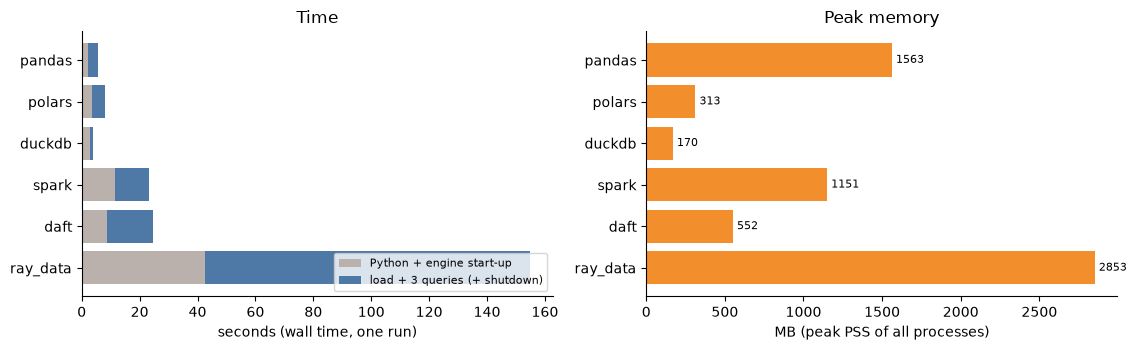

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
y = np.arange(len(ENGINES))
startup = table["start-up"]
rest = table["wall s"] - startup
ax[0].barh(y, startup, color="#BAB0AC", label="Python + engine start-up")
ax[0].barh(y, rest, left=startup, color="#4E79A7", label="load + 3 queries (+ shutdown)")
ax[0].set(yticks=y, yticklabels=ENGINES, xlabel="seconds (wall time, one run)", title="Time")
ax[0].invert_yaxis(); ax[0].legend(loc="lower right", fontsize=8)
ax[1].barh(y, table["peak MB"], color="#F28E2B")
ax[1].set(yticks=y, yticklabels=ENGINES, xlabel="MB (peak PSS of all processes)", title="Peak memory")
ax[1].invert_yaxis()
for i, v in enumerate(table["peak MB"]):
    ax[1].text(v, i, f" {v}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

*Insight: DuckDB was the fastest engine (3.81 s) and used the least memory (170 MB). The pandas run was second (5.74 s), but its peak was 1,563 MB because it loads the columns into memory first. Polars needed 313 MB. Spark spent 11.63 s of its 23.34 s on start-up (the JVM), and Daft 8.58 s of its 24.47 s. Ray Data was the slowest (154.95 s, about 40x DuckDB) and used the most memory (2,853 MB). It starts a local Ray instance and moves pandas batches between worker processes, a cost that pays off only on a cluster.*

## 5. Choosing an Engine

The numbers above are for 6 million rows on one 4-core machine, and local timings are indicative. The ranking
changes with the data size and the hardware:

| Situation | Good choice | Why |
| :--- | :--- | :--- |
| Data fits in memory of one machine (up to tens of GB), DataFrame code | **Polars** (lazy) | multi-threaded Rust, query optimizer, low memory |
| Same size, SQL, files in a lake, analytics in a notebook or an app | **DuckDB** | embedded SQL database, spills to disk, reads Parquet/Delta/Iceberg directly |
| Small data, existing code, plotting, many libraries | **pandas** | the common interface; single-threaded and memory-hungry on large data |
| Data larger than one machine (TB), many users, a lakehouse platform | **Spark** | distributed, fault tolerant, Delta/Iceberg writes, Structured Streaming, SQL governance (Unity Catalog) |
| Python ML workloads: batch inference, preprocessing on CPU + GPU, training data loading | **Ray Data** | schedules Python functions and models over a cluster with GPUs; streams batches |
| Multimodal data: images, audio, documents, embeddings, URLs | **Daft** | native types for images and tensors, Rust engine, runs locally or on Ray |
| Streaming | Spark Structured Streaming, Flink (M12) | the single-machine engines here are batch engines |

Spark is still the right choice when the data does not fit on one machine, when many jobs and teams share one
platform, when a job must survive the loss of a machine, and when the company already runs a Spark lakehouse.
For one analyst with a few GB of Parquet, a single-machine engine is simpler and faster.

## Real-World Use Case or Analogy

Choosing an engine is like **choosing a vehicle**. A bicycle (pandas) is perfect for short trips. A sports car
(Polars, DuckDB) is the fastest way to move a few people across town. A fleet of trucks (Spark, Ray) is slower to
start and needs drivers and planning, but it is the only way to move a warehouse. You do not take a truck to buy
bread.

Companies mix the engines. A common pattern: Spark jobs build the large lakehouse tables every night, analysts
query extracts of them with DuckDB or Polars on their laptops, and ML teams use Ray Data to run batch inference
with GPU models over the same Parquet files.